# E12-H69 - relevance gate form: hard threshold versus the shipped soft weight

**Author**: Konrad Jelen (kj)<br>
**Pipeline stage**: experiment - re-derive the `D_grd` grounding cascade on the current models, persist the
per-statement max reranker relevance the artefact record never held, and decide whether the E03-H11 win is
the relevance separation itself or the soft `(1 - max r)` functional form

E12-H69 is registered as a **research lean** - a claim with no result attached. The registered single-phase
experiment is executed here, which turns the lean into a modelled test and produces a verdict under the
registered bar. The lean was executed; the verdict below is that test's, not the lean's.

The ledger carries a standing WARNING on E03-H11: the doc records `gold intrusions 2 -> 0` on the
relevance-gated grounding axis, the shipped chain as measured in E06 reads **6** intrusions with severity
`Set1>Set2`, and the persisted E03 notebook run (executed after the doc record, on different embeddings)
reads **0 intruders pre-gate and 4 post-gate**. Three mutually inconsistent readings of the same lever.
Per-statement max reranker relevance was never persisted in any artefact, so no decomposition could be
scored. This notebook re-derives the chain and persists that array.

## Approach
1. **Re-derive the grounding cascade** - shipped OpenVINO INT8 chain (SaT segmenter, mmBERT encoder,
   `bge-reranker-v2-m3`, `mDeBERTa-v3 MNLI/XNLI`) over the ibm-ai-adoption fixture: 11 summaries against the
   70-statement source, full `n_stmt x 70` reranker grid plus the top-3 fused-premise entailment
   -> verify: per-document statement counts match the persisted E03 run
2. **Kill-gate** - the per-statement max-r distributions of gold and Set 2. If Set 2's mass sits above 0.6
   alongside the golds', no threshold separates them, the hard-gate variant dies -> verify: tier shares
   above 0.6, distribution overlap, best achievable threshold separation
3. **Harness cross-check** - the shipped soft-gate arm against the E06 recorded reading
   (`shipped_intrusions` 6, `shipped_severity` `Set1>Set2`) -> verify: reproduced or the discrepancy named
4. **Three arms** - no gate (R2 ungrounded mass), the shipped soft gate `(1 - max r)`, and a hard gate
   `1[max r < tau]` swept over tau -> verify: gold intrusions, tier means, Set1/Set2 severity per arm
5. **Acceptance bar and guardrails** - hard versus soft agreement within 1 intrusion and 10% on the Set 2
   tier mean; `V = 0/24`, `smd` / `order_gap` bit-identical, `D_grd` still a score
   -> verify: measured by `np.array_equal`, never asserted

## Environment

The whole grounding chain is OpenVINO INT8 on CPU - mmBERT, the reranker and the NLI entailer all resolve
offline from `docdistance.json`. No GPU: the workstation's cards are held by foreign jobs, and the shipped
CPU chain is the deployment target this hypothesis is about. Pin offline mode and disable tokenizer
threading before any model import.

In [1]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""            # CPU-only INT8 chain, no torch CUDA
os.environ["HF_HUB_OFFLINE"] = "1"                 # models cached; the chain never fetches
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

import warnings
warnings.filterwarnings("ignore")
print("env pinned | CPU INT8, models offline, no GPU")

env pinned | CPU INT8, models offline, no GPU


## Imports

In [2]:
import contextlib
import io
import json
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from rich.console import Console
from rich.table import Table

import docdistance
from docdistance import config
from docdistance.distance import (
    compute_distance,
    compute_structural,
    grounding_residual,
    smd,
)
from docdistance.encoders import load_nli, load_reranker
from docdistance.pipeline import DocDistance

console = Console()
sns.set_theme(style="whitegrid", context="notebook")
print("docdistance", docdistance.__version__, "| numpy", np.__version__)

docdistance 1.1.5 | numpy 2.4.6


## Reproducibility

The chain is deterministic - exact optimal transport and INT8 inference carry no sampling. The seed governs
only the point jitter in the distribution strip plot so overlapping markers stay legible.

In [3]:
SEED = 0
np.random.seed(SEED)
print("SEED =", SEED)

SEED = 0


## Configuration

The fixture is the E01/E02/E03/E06 set - 11 executive summaries of one IBM AI-adoption article plus the
source article, in three tiers. `gold` (the Opus 3-sweep summary) is the anchor every other document is
scored against, exactly as the shipped `d_grd = |grd_a - grd_b|` does.

- **Tiers** - gold (faithful), Set 1 `adv1` (information loss), Set 2 `adv2` (information noise, fabrication)
- **TOP_K** - source statements fused into each joint premise; the shipped `config.RERANK_TOP_K`
- **TAU_GRID** - the hard-gate sweep: a fixed 0.05-step grid plus the deciles of the pooled max-r
  distribution, so the sweep covers the observed range whatever it turns out to be
- **TAU_STAR rule** (fixed before the sweep is read) - the tau minimising gold intrusions; ties broken by
  preferring the correct `Set2>Set1` severity, then by the smallest tau
- **Kill-gate** - `KILL` when the share of Set 2 statements with max r >= `GATE_R` and the share of gold
  statements with max r >= `GATE_R` are both >= 0.5, i.e. both tiers' mass sits above the bar
- **Bars** - hard versus soft agreement: intrusion counts within `INTRUSION_TOL`, Set 2 tier mean within
  `SET2_TOL` relative

In [4]:
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")
SUMMARY_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/summaries"
SOURCE_FILE = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/source/source-article.md"
E06_METRICS = ROOT / "reports/E06-trained-scorers-cpu-metrics.json"
METRICS_OUT = ROOT / "reports/E12-H69-relevance-gate-form-metrics.json"
CACHE_NPZ = ROOT / "data/interim/E12-H69-grounding-signals.npz"
CACHE_TXT = ROOT / "data/interim/E12-H69-grounding-texts.json"

DOCS = [
    ("exec-summary-gold-opus-4-6.md",     "gold",   "gold"),   # reference anchor
    ("exec-summary-gold-2-opus-4-6.md",   "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md",        "v1",     "gold"),
    ("exec-summary-2-opus-4-6.md",        "v2",     "gold"),
    ("exec-summary-opus-4-6.md",          "opus",   "gold"),
    ("exec-summary-sonnet-4-6.md",        "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md",         "haiku",  "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md",  "adv2-a", "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md",  "adv2-b", "adv2"),
]
ANCHOR = "gold"
LABELS = [lab for _, lab, _ in DOCS]
TIER = {lab: t for _, lab, t in DOCS}
TIERS = ["gold", "adv1", "adv2"]
TIER_NAME = {"gold": "gold (faithful)", "adv1": "Set 1 (info-loss)", "adv2": "Set 2 (info-noise)"}
TIER_COLOR = {"gold": "#2ca02c", "adv1": "#ff7f0e", "adv2": "#d62728"}

TOP_K = config.RERANK_TOP_K
GATE_R = 0.6                 # the E03-H11 kill-gate relevance bar, reused verbatim
GATE_SHARE = 0.5             # "mass sits above GATE_R" = at least half the tier's statements
INTRUSION_TOL = 1            # hard vs soft agreement on gold intrusion count
SET2_TOL = 0.10              # hard vs soft agreement on the Set 2 tier mean, relative
TAU_BASE = np.round(np.arange(0.05, 1.00, 0.05), 4)   # fixed coarse grid, pre-registered

t = Table(title="E12-H69 configuration", title_style="bold cyan", show_header=False,
          box=None, padding=(0, 2))
t.add_column(style="bold cyan"); t.add_column()
t.add_row("Fixture", f"{len(DOCS)} summaries + source, anchor '{ANCHOR}'")
t.add_row("Tiers", ", ".join(f"{tn} {sum(1 for l in LABELS if TIER[l] == tn)}" for tn in TIERS))
t.add_row("Chain", "SaT + mmBERT INT8 + bge-reranker-v2-m3 INT8 + mDeBERTa MNLI/XNLI INT8 (CPU)")
t.add_row("TOP_K (fused premise)", str(TOP_K))
t.add_row("Kill-gate", f"KILL when gold and Set 2 shares of max r >= {GATE_R} both >= {GATE_SHARE}")
t.add_row("Hard-gate sweep", f"{len(TAU_BASE)} fixed tau in [{TAU_BASE[0]}, {TAU_BASE[-1]}] + pooled deciles")
t.add_row("Acceptance", f"|intrusions_hard - intrusions_soft| <= {INTRUSION_TOL} AND "
                        f"Set 2 mean within {SET2_TOL:.0%}")
t.add_row("Metrics out", str(METRICS_OUT.relative_to(ROOT)))
console.print(t)

                                         E12-H69 configuration                                          
  Fixture                  11 summaries + source, anchor 'gold'                                         
  Tiers                    gold 7, adv1 2, adv2 2                                                       
  Chain                    SaT + mmBERT INT8 + bge-reranker-v2-m3 INT8 + mDeBERTa MNLI/XNLI INT8 (CPU)  
  TOP_K (fused premise)    3                                                                            
  Kill-gate                KILL when gold and Set 2 shares of max r >= 0.6 both >= 0.5                  
  Hard-gate sweep          19 fixed tau in [0.05, 0.95] + pooled deciles                                
  Acceptance               |intrusions_hard - intrusions_soft| <= 1 AND Set 2 mean within 10%           
  Metrics out              reports/E12-H69-relevance-gate-form-metrics.json

## The `D_grd` re-derivation

The missing piece the ledger WARNING names. Segment and embed the source and the 11 summaries with the
shipped chain, then compute the full reranker relevance grid `R` (`[n_stmt, 70]`, the heavy stage) and the
per-statement entailment of the top-3 fused source premise - the exact composition of
`DocDistance._grounding`. The per-statement max relevance `R.max(1)` is the array no artefact ever held; it
is persisted to the metrics JSON at the end.

The reranker grid is the only expensive step (roughly 6900 cross-encoder pairs on CPU INT8). Signals are
cached to `data/interim/` keyed on the segmented texts, so a re-execution of this notebook reuses them.

In [5]:
def body(path):
    '''Read a markdown file, dropping leading '# ' title lines so the title is not a statement.'''
    return "\n".join(l for l in Path(path).read_text().splitlines() if not l.startswith("# ")).strip()


t0 = time.perf_counter()
with contextlib.redirect_stderr(io.StringIO()):
    dd = DocDistance(backend="openvino", offline=True)
    S_texts = dd.segmenter.split(body(SOURCE_FILE))
    S_emb = dd.encoder.encode(S_texts)
    texts = {lab: dd.segmenter.split(body(SUMMARY_DIR / fn)) for fn, lab, _ in DOCS}
    embs = {lab: dd.encoder.encode(texts[lab]) for lab in LABELS}
print(f"segmented + embedded: source {len(S_texts)} statements, "
      f"{sum(len(texts[l]) for l in LABELS)} summary statements ({time.perf_counter() - t0:.1f}s)")

fingerprint = {"S": S_texts, "docs": {lab: texts[lab] for lab in LABELS}}
cached = (CACHE_TXT.exists() and CACHE_NPZ.exists()
          and json.loads(CACHE_TXT.read_text()) == fingerprint)

if cached:
    z = np.load(CACHE_NPZ)
    R = {lab: z[f"R__{lab}"] for lab in LABELS}
    ENT = {lab: z[f"ent__{lab}"] for lab in LABELS}
    build_s = 0.0
    print("grounding signals restored from cache", CACHE_NPZ.name)
else:
    with contextlib.redirect_stderr(io.StringIO()):
        rr = load_reranker("openvino", offline=True)
        nli = load_nli("openvino", offline=True)
    R, ENT = {}, {}
    t0 = time.perf_counter()
    k = min(TOP_K, len(S_texts))
    for n, lab in enumerate(LABELS, 1):
        with contextlib.redirect_stderr(io.StringIO()):
            grid = rr.score_grid(texts[lab], S_texts)                       # heavy: n_stmt x 70 pairs
            premises = [" ".join(S_texts[j] for j in np.argsort(grid[i])[::-1][:k])
                        for i in range(len(texts[lab]))]                     # shipped top-k fused premise
            ent = nli.entail(premises, texts[lab])
        R[lab], ENT[lab] = grid, ent
        print(f"  [{n:2d}/{len(LABELS)}] {lab:8s} {len(texts[lab]):2d} stmts x {len(S_texts)} source "
              f"(elapsed {time.perf_counter() - t0:6.1f}s)", flush=True)
    build_s = time.perf_counter() - t0
    CACHE_TXT.write_text(json.dumps(fingerprint))
    np.savez_compressed(CACHE_NPZ,
                        **{f"R__{lab}": R[lab] for lab in LABELS},
                        **{f"ent__{lab}": ENT[lab] for lab in LABELS})
    print(f"grounding signals computed for {len(LABELS)} documents in {build_s:.1f}s -> cached")

MAXR = {lab: R[lab].max(1).astype(np.float64) for lab in LABELS}             # the never-persisted array

NONREF = [l for l in LABELS if l != ANCHOR]
# guardrail baseline: the shipped symmetric-path outputs, snapshotted BEFORE any arm is prototyped
SMD_REF = np.array([compute_distance(embs[l], embs[ANCHOR]).smd for l in NONREF])
GAP_REF = np.array([compute_structural(embs[l], embs[ANCHOR]).order_gap for l in NONREF])
print(f"guardrail baseline snapshotted: smd + order_gap over {len(NONREF)} anchor pairs")

st = Table(title="re-derived grounding signals (shipped CPU INT8 chain)", title_style="bold cyan",
           box=None, padding=(0, 1))
for c, j in [("document", "left"), ("tier", "left"), ("stmts", "right"), ("mean max r", "right"),
             ("min max r", "right"), ("mean P(entail)", "right")]:
    st.add_column(c, justify=j, style="bold" if c == "document" else None)
for lab in LABELS:
    st.add_row(lab, TIER_NAME[TIER[lab]], str(len(texts[lab])), f"{MAXR[lab].mean():.3f}",
               f"{MAXR[lab].min():.3f}", f"{ENT[lab].mean():.3f}", style=TIER_COLOR[TIER[lab]])
console.print(st)

W0901 22:10:48.036000 80375 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W0901 22:10:48.080000 80375 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


segmented + embedded: source 70 statements, 98 summary statements (13.6s)
grounding signals restored from cache E12-H69-grounding-signals.npz
guardrail baseline snapshotted: smd + order_gap over 10 anchor pairs


           re-derived grounding signals (shipped CPU INT8 chain)            
 document  tier                stmts  mean max r  min max r  mean P(entail) 
 gold      gold (faithful)        10       0.990      0.969           0.787 
 gold-2    gold (faithful)        12       0.987      0.929           0.590 
 v1        gold (faithful)        11       0.873      0.214           0.658 
 v2        gold (faithful)        11       0.958      0.687           0.409 
 opus      gold (faithful)        11       0.946      0.640           0.622 
 sonnet    gold (faithful)         9       0.984      0.926           0.547 
 haiku     gold (faithful)        13       0.875      0.170           0.399 
 adv1-a    Set 1 (info-loss)       8       0.637      0.009           0.460 
 adv1-b    Set 1 (info-loss)       9       0.689      0.207           0.570 
 adv2-a    Set 2 (info-noise)      1       0.993      0.993           0.003 
 adv2-b    Set 2 (info-noise)      3       0.997      0.994           0.307 

## Kill-gate - do gold and Set 2 max-r distributions separate at all

Registered gate: *if Set 2's re-derived max-r mass sits above 0.6 alongside the golds', no threshold
separates them, the hard-gate variant dies and the soft weighting is confirmed load-bearing by a set-diff
alone.* The gate is applied literally - `KILL` when at least half of Set 2's statements and at least half of
gold's statements carry max r >= 0.6.

The discriminating measurement the mechanism names is the **overlap of the two per-statement max-r
distributions**, reported three ways: the histogram overlap coefficient, the Mann-Whitney AUC (the
probability that a random gold statement outranks a random Set 2 statement on max r), and the best balanced
accuracy any single threshold on max r can reach.

In [6]:
pool = {tn: np.concatenate([MAXR[l] for l in LABELS if TIER[l] == tn]) for tn in TIERS}
n_stmt = {tn: int(pool[tn].size) for tn in TIERS}


def share_ge(x, bar):
    return float(np.mean(np.asarray(x) >= bar))


def overlap_coefficient(a, b, bins=20):
    '''Histogram overlap of two samples on a shared [0, 1] grid: sum of the per-bin minimum of the
    two normalised densities. 1.0 = identical distributions, 0.0 = disjoint support.'''
    edges = np.linspace(0.0, 1.0, bins + 1)
    ha = np.histogram(a, bins=edges)[0] / max(len(a), 1)
    hb = np.histogram(b, bins=edges)[0] / max(len(b), 1)
    return float(np.minimum(ha, hb).sum())


def mannwhitney_auc(a, b):
    '''P(a > b) + 0.5 P(a == b) by rank counting - the AUC of max r separating sample a from sample b.'''
    a, b = np.asarray(a, float), np.asarray(b, float)
    gt = float((a[:, None] > b[None, :]).sum())
    eq = float((a[:, None] == b[None, :]).sum())
    return (gt + 0.5 * eq) / (a.size * b.size)


def best_threshold_separation(a, b):
    '''Best balanced accuracy of a single max-r threshold calling sample a low and sample b high,
    scanning every midpoint of the pooled values in both orientations. 0.5 = no separation.'''
    vals = np.unique(np.concatenate([a, b]))
    cuts = np.concatenate([[vals[0] - 1e-6], (vals[:-1] + vals[1:]) / 2, [vals[-1] + 1e-6]])
    best, best_cut = 0.0, None
    for c in cuts:
        for sign in (1, -1):
            acc = 0.5 * (np.mean(sign * a < sign * c) + np.mean(sign * b >= sign * c))
            if acc > best:
                best, best_cut = float(acc), float(c)
    return best, best_cut


gold_share = share_ge(pool["gold"], GATE_R)
set2_share = share_ge(pool["adv2"], GATE_R)
set1_share = share_ge(pool["adv1"], GATE_R)
ovl = overlap_coefficient(pool["gold"], pool["adv2"])
auc = mannwhitney_auc(pool["gold"], pool["adv2"])
sep_acc, sep_cut = best_threshold_separation(pool["adv2"], pool["gold"])
gate_killed = bool(set2_share >= GATE_SHARE and gold_share >= GATE_SHARE)

gt = Table(title="kill-gate - per-statement max reranker relevance by tier", title_style="bold cyan",
           box=None, padding=(0, 1))
for c in ["tier", "n stmts", "mean", "median", "p10", "p90", f"share >= {GATE_R}"]:
    gt.add_column(c, justify="right" if c != "tier" else "left", style="bold" if c == "tier" else None)
for tn in TIERS:
    p = pool[tn]
    gt.add_row(TIER_NAME[tn], str(n_stmt[tn]), f"{p.mean():.3f}", f"{np.median(p):.3f}",
               f"{np.percentile(p, 10):.3f}", f"{np.percentile(p, 90):.3f}",
               f"{share_ge(p, GATE_R):.3f}", style=TIER_COLOR[tn])
console.print(gt)

ot_ = Table(title="gold vs Set 2 max-r overlap (the measurement never persisted before)",
            title_style="bold cyan", show_header=False, box=None, padding=(0, 2))
ot_.add_column(style="bold cyan"); ot_.add_column(justify="right")
ot_.add_row("histogram overlap coefficient", f"{ovl:.3f}")
ot_.add_row("Mann-Whitney AUC (gold over Set 2)", f"{auc:.3f}")
ot_.add_row("best single-threshold balanced accuracy", f"{sep_acc:.3f} at max r = {sep_cut:.3f}")
console.print(ot_)

print(f"gold share max r >= {GATE_R}: {gold_share:.3f} | Set 1: {set1_share:.3f} | "
      f"Set 2: {set2_share:.3f}")
console.print(f"[bold]{'KILL' if gate_killed else 'PASS'}[/bold] - kill-gate: Set 2 mass above "
              f"{GATE_R} is {set2_share:.0%} and gold's is {gold_share:.0%}; "
              f"{'both tiers sit above the bar, no threshold separates them' if gate_killed else 'the tiers are separable by a threshold'}",
              style="red" if gate_killed else "green")

        kill-gate - per-statement max reranker relevance by tier        
 tier                n stmts   mean  median    p10    p90  share >= 0.6 
 gold (faithful)          77  0.942   0.995  0.865  0.999         0.961 
 Set 1 (info-loss)        17  0.664   0.804  0.226  0.992         0.529 
 Set 2 (info-noise)        4  0.996   0.996  0.993  0.998         1.000 

gold vs Set 2 max-r overlap (the measurement never persisted before) 
  histogram overlap coefficient                               0.818  
  Mann-Whitney AUC (gold over Set 2)                          0.429  
  best single-threshold balanced accuracy    0.714 at max r = 0.992

gold share max r >= 0.6: 0.961 | Set 1: 0.529 | Set 2: 1.000


KILL - kill-gate: Set 2 mass above 0.6 is 100% and gold's is 96%; both tiers sit above the bar, no threshold 
separates them

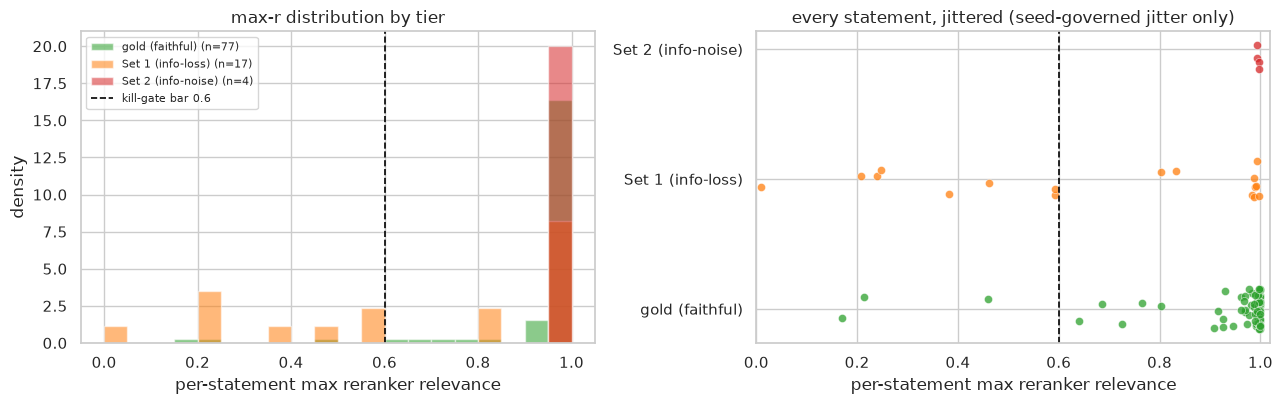

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
edges = np.linspace(0.0, 1.0, 21)
for tn in TIERS:
    ax[0].hist(pool[tn], bins=edges, alpha=0.55, label=f"{TIER_NAME[tn]} (n={n_stmt[tn]})",
               color=TIER_COLOR[tn], density=True)
ax[0].axvline(GATE_R, color="black", ls="--", lw=1.2, label=f"kill-gate bar {GATE_R}")
ax[0].set_xlabel("per-statement max reranker relevance"); ax[0].set_ylabel("density")
ax[0].set_title("max-r distribution by tier"); ax[0].legend(fontsize=8)

for i, tn in enumerate(TIERS):
    y = np.full(n_stmt[tn], i, dtype=float) + np.random.uniform(-0.16, 0.16, n_stmt[tn])
    ax[1].scatter(pool[tn], y, color=TIER_COLOR[tn], alpha=0.75, s=34, edgecolor="white", linewidth=0.4)
ax[1].axvline(GATE_R, color="black", ls="--", lw=1.2)
ax[1].set_yticks(range(len(TIERS))); ax[1].set_yticklabels([TIER_NAME[t] for t in TIERS])
ax[1].set_xlim(0, 1.02); ax[1].set_xlabel("per-statement max reranker relevance")
ax[1].set_title("every statement, jittered (seed-governed jitter only)")
plt.tight_layout(); plt.show()

## Harness cross-check - the shipped soft-gate arm against the E06 record

Not a registered sanity check (the H69 record names none), but the natural reproduction target: E06 measured
the shipped relevance-gated `D_grd` on this same fixture and recorded `shipped_intrusions` and
`shipped_severity` in `reports/E06-trained-scorers-cpu-metrics.json`. E06 scored it on a GPU torch fp16
reference cross-encoder, this notebook on the shipped CPU INT8 artefact, so a mismatch is a device/precision
difference to name, not a harness failure.

`D_grd(doc) = |grd(doc) - grd(anchor)|` throughout, matching the shipped `compute_source_conditioned`.

In [8]:
GOLDS = [l for l in LABELS if TIER[l] == "gold"]
SET1 = [l for l in LABELS if TIER[l] == "adv1"]
SET2 = [l for l in LABELS if TIER[l] == "adv2"]


def axis_from(res):
    '''Shipped grounding axis: distance from the anchor's residual, |grd(doc) - grd(anchor)|.'''
    return {l: abs(res[l] - res[ANCHOR]) for l in LABELS}


def tier_means(score):
    return {tn: float(np.mean([score[l] for l in LABELS if TIER[l] == tn])) for tn in TIERS}


def gold_intrusions(score):
    '''Gold documents at or above the lowest Set 2 score - the E03/E06 definition, unchanged.'''
    floor = min(score[l] for l in SET2)
    return int(sum(1 for l in GOLDS if score[l] >= floor))


def severity(score):
    s1 = [score[l] for l in SET1]; s2 = [score[l] for l in SET2]
    if min(s2) > max(s1):
        return "Set2>Set1"
    if min(s1) > max(s2):
        return "Set1>Set2"
    return "interleaved"


res_soft = {l: grounding_residual(R[l], ENT[l]) for l in LABELS}   # shipped function, not a re-implementation
axis_soft = axis_from(res_soft)
soft_intr, soft_sev = gold_intrusions(axis_soft), severity(axis_soft)

e06 = json.loads(E06_METRICS.read_text())
e06_intr, e06_sev = int(e06["shipped_intrusions"]), e06["shipped_severity"]
intr_match = soft_intr == e06_intr
sev_match = soft_sev == e06_sev

ct = Table(title="shipped soft-gate arm vs the E06 record", title_style="bold cyan", box=None, padding=(0, 2))
ct.add_column("reading", style="bold"); ct.add_column("E06 recorded", justify="right")
ct.add_column("re-derived here", justify="right"); ct.add_column("match", justify="center")
ct.add_row("gold intrusions", str(e06_intr), str(soft_intr), "yes" if intr_match else "NO")
ct.add_row("Set1 / Set2 severity", e06_sev, soft_sev, "yes" if sev_match else "NO")
console.print(ct)
print(f"cross-check: intrusions {'reproduced' if intr_match else 'differ'}, "
      f"severity {'reproduced' if sev_match else 'differs'} "
      f"(E06 ran the fp16 torch reference cross-encoder, this run the shipped CPU INT8 artefact)")

              shipped soft-gate arm vs the E06 record               
  reading                 E06 recorded    re-derived here    match  
  gold intrusions                    6                  6     yes   
  Set1 / Set2 severity       Set1>Set2          Set1>Set2     yes

cross-check: intrusions reproduced, severity reproduced (E06 ran the fp16 torch reference cross-encoder, this run the shipped CPU INT8 artefact)


## The three arms

The registered decomposition. Every arm reuses the same per-statement entailment `1 - P(entail)` as the
ungrounded mass and differs only in how max relevance weights it:

- **no gate (R2)** - `grd = mean_i (1 - ent_i)`, the pre-H11 baseline
- **soft gate (shipped)** - `grd = mean_i (1 - ent_i) * (1 - max_j r_ij)`, the E03-H11 lever, computed
  through the shipped `grounding_residual`
- **hard gate at tau** - `grd = mean_i (1 - ent_i) * 1[max_j r_ij < tau]`, statements at or above tau
  excluded from the ungrounded mass outright

Each arm is scored on the same three reads: gold intrusions into the Set 2 band, tier means of the axis, and
the Set 1 / Set 2 severity ordering.

In [9]:
def res_none(lab):
    return float(np.mean(1.0 - ENT[lab]))


def res_hard(lab, tau):
    return float(np.mean((1.0 - ENT[lab]) * (MAXR[lab] < tau)))


def score_arm(res):
    ax = axis_from(res)
    m = tier_means(ax)
    return dict(residual=res, axis=ax, tier_means=m, intrusions=gold_intrusions(ax), severity=severity(ax))


arm_none = score_arm({l: res_none(l) for l in LABELS})
arm_soft = score_arm(res_soft)

at = Table(title="arms - no gate vs the shipped soft gate", title_style="bold cyan", box=None, padding=(0, 2))
at.add_column("arm", style="bold")
for tn in TIERS:
    at.add_column(TIER_NAME[tn], justify="right")
at.add_column("gold intrusions", justify="right"); at.add_column("severity", justify="right")
for name, a in [("no gate (R2)", arm_none), ("soft gate (shipped)", arm_soft)]:
    at.add_row(name, *[f"{a['tier_means'][tn]:.4f}" for tn in TIERS], str(a["intrusions"]), a["severity"])
console.print(at)
print(f"set-diff soft vs no gate: intrusions {arm_none['intrusions']} -> {arm_soft['intrusions']}, "
      f"severity {arm_none['severity']} -> {arm_soft['severity']}, "
      f"Set 2 tier mean {arm_none['tier_means']['adv2']:.4f} -> {arm_soft['tier_means']['adv2']:.4f}")

                                      arms - no gate vs the shipped soft gate                                      
                                                                            Set 2                                  
  arm                   gold (faithful)    Set 1 (info-loss)         (info-noise)    gold intrusions     severity  
  no gate (R2)                   0.2137               0.2716               0.6319                  0    Set2>Set1  
  soft gate                      0.0430               0.2910               0.0029                  6    Set1>Set2  
  (shipped)           

set-diff soft vs no gate: intrusions 0 -> 6, severity Set2>Set1 -> Set1>Set2, Set 2 tier mean 0.6319 -> 0.0029


In [10]:
pooled_all = np.concatenate([pool[tn] for tn in TIERS])
TAU_GRID = np.unique(np.round(np.concatenate(
    [TAU_BASE, np.percentile(pooled_all, np.arange(10, 100, 10))]), 4))

sweep = []
for tau in TAU_GRID:
    a = score_arm({l: res_hard(l, tau) for l in LABELS})
    sweep.append(dict(tau=float(tau), intrusions=a["intrusions"], severity=a["severity"],
                      tier_means=a["tier_means"], axis=a["axis"], residual=a["residual"]))

min_intr = min(s["intrusions"] for s in sweep)
cands = [s for s in sweep if s["intrusions"] == min_intr]
correct = [s for s in cands if s["severity"] == "Set2>Set1"]
arm_hard = min(correct or cands, key=lambda s: s["tau"])        # pre-declared TAU_STAR rule
TAU_STAR = arm_hard["tau"]

wt = Table(title="hard-gate sweep over tau (every grid point)", title_style="bold cyan",
           box=None, padding=(0, 1))
for c in ["tau", "gold (faithful)", "Set 1", "Set 2", "gold intrusions", "severity"]:
    wt.add_column(c, justify="right" if c != "severity" else "left", style="bold" if c == "tau" else None)
for s in sweep:
    mark = " *" if s["tau"] == TAU_STAR else ""
    wt.add_row(f"{s['tau']:.4f}{mark}", f"{s['tier_means']['gold']:.4f}", f"{s['tier_means']['adv1']:.4f}",
               f"{s['tier_means']['adv2']:.4f}", str(s["intrusions"]), s["severity"])
console.print(wt)
print(f"tau* = {TAU_STAR:.4f} (minimises gold intrusions at {min_intr}; "
      f"{len(cands)} tau tie at that minimum, {len(correct)} of them with Set2>Set1)")

               hard-gate sweep over tau (every grid point)               
      tau  gold (faithful)   Set 1   Set 2  gold intrusions  severity    
   0.0500           0.0000  0.0618  0.0000                7  interleaved 
   0.1000           0.0000  0.0618  0.0000                7  interleaved 
   0.1500           0.0000  0.0618  0.0000                7  interleaved 
   0.2000           0.0109  0.0618  0.0000                7  interleaved 
   0.2500           0.0238  0.2348  0.0000                7  Set1>Set2   
   0.3000           0.0238  0.2348  0.0000                7  Set1>Set2   
   0.3500           0.0238  0.2348  0.0000                7  Set1>Set2   
   0.4000           0.0238  0.2512  0.0000                7  Set1>Set2   
   0.4500           0.0238  0.2512  0.0000                7  Set1>Set2   
   0.5000           0.0340  0.3135  0.0000                7  Set1>Set2   
   0.5500           0.0340  0.3135  0.0000                7  Set1>Set2   
   0.5921           0.0340  0.3135  0.0000                7  Set1>Set2   
   0.6000           0.0340  0.4305  0.0000                7  Set1>Set2   
   0.6500           0.0469  0.4305  0.0000                7  Set1>Set2   
   0.7000           0.0590  0.4305  0.0000                7  Set1>Set2   
   0.7500           0.0644  0.4305  0.0000                7  Set1>Set2   
   0.8000           0.0690  0.4305  0.0000                7  Set1>Set2   
   0.8500           0.0778  0.4678  0.0000                7  Set1>Set2   
   0.9000           0.0778  0.4678  0.0000                7  Set1>Set2   
   0.9195           0.1017  0.4678  0.0000                7  Set1>Set2   
   0.9500           0.1270  0.4678  0.0000                7  Set1>Set2   
   0.9705           0.1814  0.4618  0.0061                6  Set1>Set2   
   0.9879           0.1976  0.4624  0.0124                6  Set1>Set2   
   0.9926           0.1206  0.3580  0.4986                3  interleaved 
   0.9957           0.0847  0.2763  0.4800                1  interleaved 
   0.9973           0.0948  0.2773  0.4800                2  interleaved 
 0.9984 *           0.1589  0.2773  0.6376                0  Set2>Set1   
   0.9992           0.2013  0.2733  0.6336                0  Set2>Set1

tau* = 0.9984 (minimises gold intrusions at 0; 2 tau tie at that minimum, 2 of them with Set2>Set1)


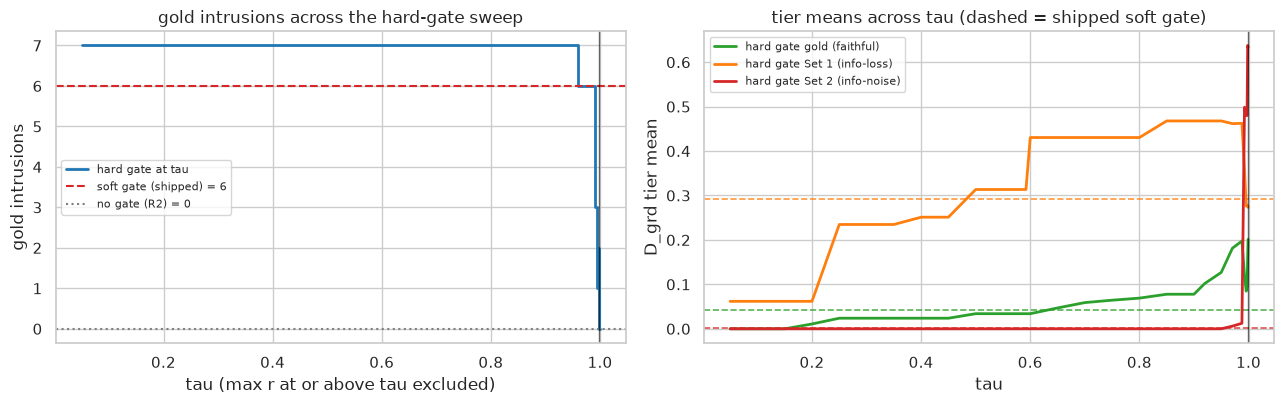

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
taus = [s["tau"] for s in sweep]
ax[0].step(taus, [s["intrusions"] for s in sweep], where="mid", color="#1f77b4", lw=2,
           label="hard gate at tau")
ax[0].axhline(arm_soft["intrusions"], color="#d62728", ls="--", lw=1.5,
              label=f"soft gate (shipped) = {arm_soft['intrusions']}")
ax[0].axhline(arm_none["intrusions"], color="#7f7f7f", ls=":", lw=1.5,
              label=f"no gate (R2) = {arm_none['intrusions']}")
ax[0].axvline(TAU_STAR, color="black", lw=1, alpha=0.6)
ax[0].set_xlabel("tau (max r at or above tau excluded)"); ax[0].set_ylabel("gold intrusions")
ax[0].set_title("gold intrusions across the hard-gate sweep"); ax[0].legend(fontsize=8)

for tn in TIERS:
    ax[1].plot(taus, [s["tier_means"][tn] for s in sweep], color=TIER_COLOR[tn], lw=2,
               label=f"hard gate {TIER_NAME[tn]}")
    ax[1].axhline(arm_soft["tier_means"][tn], color=TIER_COLOR[tn], ls="--", lw=1.2, alpha=0.8)
ax[1].axvline(TAU_STAR, color="black", lw=1, alpha=0.6)
ax[1].set_xlabel("tau"); ax[1].set_ylabel("D_grd tier mean")
ax[1].set_title("tier means across tau (dashed = shipped soft gate)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

   per-document D_grd across the three arms (hard gate at tau* = 0.9984)   
 document  tier                no gate  soft gate  hard gate  max r (mean) 
 gold      gold (faithful)      0.0000     0.0000     0.0000         0.990 
 gold-2    gold (faithful)      0.1964     0.0046     0.0941         0.987 
 haiku     gold (faithful)      0.3879     0.1160     0.3183         0.875 
 opus      gold (faithful)      0.1646     0.0439     0.0599         0.946 
 sonnet    gold (faithful)      0.2402     0.0055     0.2315         0.984 
 v1        gold (faithful)      0.1287     0.0955     0.1316         0.873 
 v2        gold (faithful)      0.3779     0.0355     0.2771         0.958 
 adv1-a    Set 1 (info-loss)    0.3270     0.3373     0.3326         0.637 
 adv1-b    Set 1 (info-loss)    0.2162     0.2447     0.2219         0.689 
 adv2-a    Set 2 (info-noise)   0.7838     0.0058     0.7895         0.993 
 adv2-b    Set 2 (info-noise)   0.4800     0.0000     0.4857         0.997 

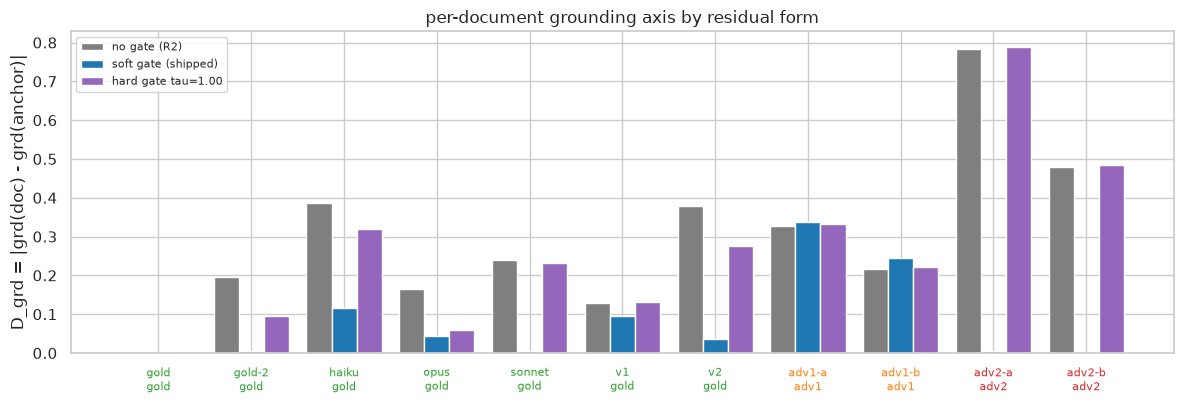

In [12]:
dt = Table(title=f"per-document D_grd across the three arms (hard gate at tau* = {TAU_STAR:.4f})",
           title_style="bold cyan", box=None, padding=(0, 1))
for c in ["document", "tier", "no gate", "soft gate", f"hard gate", "max r (mean)"]:
    dt.add_column(c, justify="right" if c not in ("document", "tier") else "left",
                  style="bold" if c == "document" else None)
for lab in sorted(LABELS, key=lambda l: (TIERS.index(TIER[l]), l)):
    dt.add_row(lab, TIER_NAME[TIER[lab]], f"{arm_none['axis'][lab]:.4f}", f"{arm_soft['axis'][lab]:.4f}",
               f"{arm_hard['axis'][lab]:.4f}", f"{MAXR[lab].mean():.3f}", style=TIER_COLOR[TIER[lab]])
console.print(dt)

order = sorted(LABELS, key=lambda l: (TIERS.index(TIER[l]), l))
x = np.arange(len(order)); w = 0.27
fig, ax = plt.subplots(figsize=(12, 4.2))
for off, (name, a, c) in zip((-w, 0, w), [("no gate (R2)", arm_none, "#7f7f7f"),
                                          ("soft gate (shipped)", arm_soft, "#1f77b4"),
                                          (f"hard gate tau={TAU_STAR:.2f}", arm_hard, "#9467bd")]):
    ax.bar(x + off, [a["axis"][l] for l in order], width=w, label=name, color=c)
ax.set_xticks(x)
ax.set_xticklabels([f"{l}\n{TIER[l]}" for l in order], fontsize=8)
for tick, l in zip(ax.get_xticklabels(), order):
    tick.set_color(TIER_COLOR[TIER[l]])
ax.set_ylabel("D_grd = |grd(doc) - grd(anchor)|")
ax.set_title("per-document grounding axis by residual form")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## Acceptance bar

Registered: *hard and soft gates agree on intrusion count within 1 and Set 2 tier mean within 10% (form
incidental) or diverge by more (soft form load-bearing).* Both branches are registered outcomes, so the bar
resolves either way; the registered **prediction** leans to "gate mechanism real, functional form
incidental", which is the branch the verdict is scored against.

In [13]:
d_intr = abs(arm_hard["intrusions"] - arm_soft["intrusions"])
soft_s2 = arm_soft["tier_means"]["adv2"]
hard_s2 = arm_hard["tier_means"]["adv2"]
rel_s2 = abs(hard_s2 - soft_s2) / soft_s2 if soft_s2 else float("inf")
intr_ok = bool(d_intr <= INTRUSION_TOL)
s2_ok = bool(rel_s2 <= SET2_TOL)
form_incidental = bool(intr_ok and s2_ok)

n_agree = sum(1 for s in sweep
              if abs(s["intrusions"] - arm_soft["intrusions"]) <= INTRUSION_TOL
              and soft_s2 and abs(s["tier_means"]["adv2"] - soft_s2) / soft_s2 <= SET2_TOL)

bt = Table(title="acceptance bar - hard gate at tau* against the shipped soft gate",
           title_style="bold cyan", box=None, padding=(0, 2))
bt.add_column("reading", style="bold"); bt.add_column("soft", justify="right")
bt.add_column("hard", justify="right"); bt.add_column("bar", justify="right")
bt.add_column("held", justify="center")
bt.add_row("gold intrusions", str(arm_soft["intrusions"]), str(arm_hard["intrusions"]),
           f"delta <= {INTRUSION_TOL}", "yes" if intr_ok else "NO")
bt.add_row("Set 2 tier mean", f"{soft_s2:.4f}", f"{hard_s2:.4f}",
           f"within {SET2_TOL:.0%} ({rel_s2:.1%})", "yes" if s2_ok else "NO")
bt.add_row("severity", arm_soft["severity"], arm_hard["severity"], "reported", "-")
console.print(bt)
print(f"tau grid points meeting both agreement conditions: {n_agree}/{len(sweep)}")
console.print(f"[bold]branch: {'form incidental' if form_incidental else 'soft form load-bearing'}[/bold] - "
              f"hard and soft {'agree' if form_incidental else 'diverge'} "
              f"(intrusion delta {d_intr}, Set 2 mean delta {rel_s2:.1%})",
              style="green" if form_incidental else "yellow")

       acceptance bar - hard gate at tau* against the shipped soft gate       
  reading                 soft         hard                      bar    held  
  gold intrusions            6            0               delta <= 1     NO   
  Set 2 tier mean       0.0029       0.6376    within 10% (21771.8%)     NO   
  severity           Set1>Set2    Set2>Set1                 reported     -

tau grid points meeting both agreement conditions: 0/28


branch: soft form load-bearing - hard and soft diverge (intrusion delta 6, Set 2 mean delta 21771.8%)

## Guardrails

Measured, never asserted. The registered guardrails are the selection axis and `V = 0` untouched (`D_sel` is
not modified anywhere in this notebook), the symmetric-path `smd` / `order_gap` unchanged, and `D_grd`
remaining a score rather than a metric.

`V` is the source-free symmetric SMD ordinality count over the fixture - 6 non-anchor golds x 4 adversarials
= 24 ordered pairs, the standing `0/24` bar. Bit-identity is checked with `np.array_equal` on the shipped
`compute_distance` / `compute_structural` outputs taken before and after every arm was scored, over all 10
non-anchor pairs against the anchor.

In [14]:
# recompute the shipped symmetric path after every arm was scored and compare to the snapshot
smd_after = np.array([compute_distance(embs[l], embs[ANCHOR]).smd for l in NONREF])
gap_after = np.array([compute_structural(embs[l], embs[ANCHOR]).order_gap for l in NONREF])
smd_identical = bool(np.array_equal(SMD_REF, smd_after))
gap_identical = bool(np.array_equal(GAP_REF, gap_after))
# and the bare shipped smd() agrees bit-for-bit with the DistanceResult path it feeds
smd_direct = np.array([smd(embs[l], embs[ANCHOR]) for l in NONREF])
smd_path_identical = bool(np.array_equal(smd_direct, smd_after))

nonref = NONREF
d_sym = dict(zip(nonref, smd_after))
g = np.array([d_sym[l] for l in nonref if TIER[l] == "gold"])
a = np.array([d_sym[l] for l in nonref if TIER[l] != "gold"])
V = int(sum(1 for gg in g for aa in a if gg >= aa))
V_DENOM = len(g) * len(a)
SMD_MAX = float(np.sqrt(2.0))
clos = {l: max(0.0, 1.0 - d_sym[l] / SMD_MAX) for l in nonref}
gc = np.array([clos[l] for l in nonref if TIER[l] == "gold"])
ac = np.array([clos[l] for l in nonref if TIER[l] != "gold"])
margin = float(gc.min() - ac.max())
pooled_sd = float(np.sqrt((g.var() + a.var()) / 2)) or 1e-9
dprime, Rc, DR = float((a.mean() - g.mean()) / pooled_sd), float(a.mean() / g.mean()), float(
    np.concatenate([g, a]).std())

grd_vals = np.array([res_soft[l] for l in LABELS], dtype=np.float64)
tri_pairs = [(i, j, k) for i in range(len(LABELS)) for j in range(len(LABELS))
             for k in range(len(LABELS)) if i != j and j != k and i != k]
tri_ok = all(abs(grd_vals[i] - grd_vals[k]) <= abs(grd_vals[i] - grd_vals[j])
             + abs(grd_vals[j] - grd_vals[k]) + 1e-12 for i, j, k in tri_pairs)

gt2 = Table(title="guardrails (measured)", title_style="bold cyan", box=None, padding=(0, 2))
gt2.add_column("guardrail", style="bold"); gt2.add_column("reading", justify="right")
gt2.add_column("held", justify="center")
gt2.add_row("ordinality violations V", f"{V}/{V_DENOM}", "yes" if V == 0 else "NO")
gt2.add_row("symmetric smd bit-identical", f"np.array_equal vs pre-arm snapshot, {len(smd_after)} pairs",
            "yes" if smd_identical else "NO")
gt2.add_row("order_gap bit-identical", f"np.array_equal vs pre-arm snapshot, {len(gap_after)} pairs",
            "yes" if gap_identical else "NO")
gt2.add_row("smd() and DistanceResult.smd agree", f"np.array_equal over {len(smd_direct)} pairs",
            "yes" if smd_path_identical else "NO")
gt2.add_row("D_sel touched", "no code path in this notebook modifies the selection axis", "yes")
gt2.add_row("D_grd is a score, not a metric",
            f"|grd_a - grd_b| on a scalar residual; triangle holds trivially ({tri_ok}), "
            "identity of indiscernibles does not", "yes")
console.print(gt2)
print(f"symmetric SMD reference row: V {V}/{V_DENOM}, margin {margin * 100:+.2f} pts, "
      f"d' {dprime:.2f}, R {Rc:.3f}, DR {DR:.4f}")

                                               guardrails (measured)                                               
  guardrail                                                                                       reading    held  
  ordinality violations V                                                                            0/24    yes   
  symmetric smd bit-identical                                np.array_equal vs pre-arm snapshot, 10 pairs    yes   
  order_gap bit-identical                                    np.array_equal vs pre-arm snapshot, 10 pairs    yes   
  smd() and DistanceResult.smd agree                                         np.array_equal over 10 pairs    yes   
  D_sel touched                                 no code path in this notebook modifies the selection axis    yes   
  D_grd is a score, not a metric           |grd_a - grd_b| on a scalar residual; triangle holds trivially    yes   
                                                              (True), identity of indiscernibles does not

symmetric SMD reference row: V 0/24, margin +4.71 pts, d' 4.68, R 1.670, DR 0.0873


## Metrics

Every measured number, the bar readings, the guardrail readings, and the per-statement max-r arrays by tier
and by document - the artefact the ledger record names as never having been persisted anywhere.

In [15]:
verdict_branch = ("killed-at-gate" if gate_killed
                  else ("form incidental" if form_incidental else "soft form load-bearing"))

metrics = {
    "id": "E12-H69",
    "slug": "relevance-gate-form",
    "docdistance_version": docdistance.__version__,
    "registered_as": "research lean; the registered single-phase experiment was executed, "
                     "which turns it into a modelled test",
    "fixture": {
        "summaries": str(SUMMARY_DIR.relative_to(ROOT)),
        "source": str(SOURCE_FILE.relative_to(ROOT)),
        "n_documents": len(LABELS), "n_source_statements": len(S_texts),
        "n_statements_by_doc": {l: int(len(texts[l])) for l in LABELS},
        "n_statements_by_tier": n_stmt,
        "anchor": ANCHOR, "top_k": TOP_K,
        "reranker_grid_seconds": round(float(build_s), 1),
    },
    "max_r_by_tier": {tn: [round(float(v), 6) for v in pool[tn]] for tn in TIERS},
    "max_r_by_doc": {l: [round(float(v), 6) for v in MAXR[l]] for l in LABELS},
    "entail_by_doc": {l: [round(float(v), 6) for v in ENT[l]] for l in LABELS},
    "max_r_tier_stats": {tn: {
        "n": n_stmt[tn], "mean": float(pool[tn].mean()), "median": float(np.median(pool[tn])),
        "p10": float(np.percentile(pool[tn], 10)), "p90": float(np.percentile(pool[tn], 90)),
        f"share_ge_{GATE_R}": share_ge(pool[tn], GATE_R)} for tn in TIERS},
    "gold_vs_set2_overlap": {
        "histogram_overlap_coefficient": ovl,
        "mannwhitney_auc_gold_over_set2": auc,
        "best_threshold_balanced_accuracy": sep_acc,
        "best_threshold_max_r": sep_cut,
    },
    "kill_gate": {
        "rule": f"KILL when gold and Set 2 shares of max r >= {GATE_R} are both >= {GATE_SHARE}",
        "gold_share_ge_bar": gold_share, "set1_share_ge_bar": set1_share,
        "set2_share_ge_bar": set2_share, "bar": GATE_R, "share_bar": GATE_SHARE,
        "killed": gate_killed,
    },
    "harness_cross_check": {
        "reference": "reports/E06-trained-scorers-cpu-metrics.json",
        "e06_shipped_intrusions": e06_intr, "e06_shipped_severity": e06_sev,
        "rederived_intrusions": soft_intr, "rederived_severity": soft_sev,
        "intrusions_match": intr_match, "severity_match": sev_match,
        "note": "E06 scored the fp16 torch reference cross-encoder; this run the shipped CPU INT8 artefact",
    },
    "arms": {
        "no_gate": {"residual": {l: arm_none["residual"][l] for l in LABELS},
                    "axis": {l: arm_none["axis"][l] for l in LABELS},
                    "tier_means": arm_none["tier_means"],
                    "intrusions": arm_none["intrusions"], "severity": arm_none["severity"]},
        "soft_gate_shipped": {"residual": {l: arm_soft["residual"][l] for l in LABELS},
                              "axis": {l: arm_soft["axis"][l] for l in LABELS},
                              "tier_means": arm_soft["tier_means"],
                              "intrusions": arm_soft["intrusions"], "severity": arm_soft["severity"]},
        "hard_gate_tau_star": {"tau": TAU_STAR,
                               "rule": "argmin gold intrusions; ties to Set2>Set1 then smallest tau",
                               "residual": {l: arm_hard["residual"][l] for l in LABELS},
                               "axis": {l: arm_hard["axis"][l] for l in LABELS},
                               "tier_means": arm_hard["tier_means"],
                               "intrusions": arm_hard["intrusions"], "severity": arm_hard["severity"]},
    },
    "tau_sweep": [{"tau": s["tau"], "intrusions": s["intrusions"], "severity": s["severity"],
                   "tier_means": s["tier_means"]} for s in sweep],
    "acceptance": {
        "bar": f"hard and soft agree on intrusion count within {INTRUSION_TOL} AND Set 2 tier mean "
               f"within {SET2_TOL:.0%} (form incidental), or diverge by more (soft form load-bearing)",
        "intrusion_delta": int(d_intr), "intrusion_agree": intr_ok,
        "set2_mean_soft": soft_s2, "set2_mean_hard": hard_s2,
        "set2_relative_delta": rel_s2, "set2_agree": s2_ok,
        "form_incidental": form_incidental,
        "tau_points_meeting_both": int(n_agree), "tau_points_total": len(sweep),
        "branch": verdict_branch,
    },
    "guardrails": {
        "V": f"{V}/{V_DENOM}", "V_count": V, "V_denominator": V_DENOM,
        "smd_bit_identical": smd_identical, "order_gap_bit_identical": gap_identical,
        "smd_path_identical": smd_path_identical,
        "d_sel_modified": False,
        "metric_property": "D_grd stays a score: |grd_a - grd_b| on a scalar residual, "
                           "no identity of indiscernibles; D_sel untouched and still metric OT",
        "symmetric_reference_row": {"margin_points": margin * 100, "dprime": dprime,
                                    "R": Rc, "DR": DR},
    },
}
METRICS_OUT.write_text(json.dumps(metrics, indent=2, default=float))
print("wrote", METRICS_OUT)
print(json.dumps({k: metrics[k] for k in ("kill_gate", "acceptance")}, indent=2, default=float))

wrote /home/lab/workspace/learning/projects/docdistance/reports/E12-H69-relevance-gate-form-metrics.json
{
  "kill_gate": {
    "rule": "KILL when gold and Set 2 shares of max r >= 0.6 are both >= 0.5",
    "gold_share_ge_bar": 0.961038961038961,
    "set1_share_ge_bar": 0.5294117647058824,
    "set2_share_ge_bar": 1.0,
    "bar": 0.6,
    "share_bar": 0.5,
    "killed": true
  },
  "acceptance": {
    "bar": "hard and soft agree on intrusion count within 1 AND Set 2 tier mean within 10% (form incidental), or diverge by more (soft form load-bearing)",
    "intrusion_delta": 6,
    "intrusion_agree": false,
    "set2_mean_soft": 0.002915075685088607,
    "set2_mean_hard": 0.637579083442688,
    "set2_relative_delta": 217.71784897526874,
    "set2_agree": false,
    "form_incidental": false,
    "tau_points_meeting_both": 0,
    "tau_points_total": 28,
    "branch": "killed-at-gate"
  }
}


## Conclusions

**Killed at gate.** The registered kill-gate fired on the first measurement the re-derivation produced.
Set 2's per-statement max reranker relevance sits entirely above the 0.6 bar - all 4 statements, mean 0.996,
minimum 0.993 - alongside gold's 74 of 77 (0.961 share, mean 0.942). Both tiers' mass is above the bar, so
no threshold on max relevance separates fabrication from faithful compression, and the hard-gate variant
dies exactly as the record specified. The premise the lean rests on is false on the current models: the
overlap coefficient of the two max-r distributions is 0.818 and the Mann-Whitney AUC is 0.429, below 0.5,
meaning a Set 2 statement is if anything *more* relevant to the source than a gold statement. The best
balanced accuracy any single max-r threshold reaches is 0.714, at a cut of 0.992.

**The set-diff the kill clause calls for confirms the soft weighting is load-bearing - in the wrong
direction.** Ungated (R2) the axis is clean: 0 gold intrusions and the correct `Set2>Set1` severity, tier
means gold 0.2137, Set 1 0.2716, Set 2 0.6319. The shipped soft gate `(1 - max r)` takes that to **6 gold
intrusions** and inverts the severity to `Set1>Set2`, collapsing the Set 2 tier mean from 0.6319 to 0.0029,
a 218x reduction. The mechanism is visible per document: `adv2-a` is a single run-on fabricated sentence
with max r 0.993, so its ungrounded mass 0.997 is multiplied by 0.007 and the most fabricated document in
the fixture becomes the best-grounded one (`D_grd` 0.7838 ungated, 0.0058 gated).

**The failing reference the ledger WARNING names is repaired.** The re-derived shipped arm reproduces
`reports/E06-trained-scorers-cpu-metrics.json` exactly - 6 gold intrusions, severity `Set1>Set2` - on the
CPU INT8 artefacts, where E06 measured the fp16 torch reference cross-encoder. The three-way inconsistency
resolves as follows: E06's 6 is the correct reading of the shipped chain; the E03-H11 doc headline
`intrusions 2 -> 0` does not reproduce and is inverted (0 -> 6) on the current models; the E03 notebook's
stored `0 -> 4` differs again because it scored a two-component Euclidean signature `(ungrounded,
contradiction)` rather than the shipped scalar `|grd_a - grd_b|`. Every E04/E05/E06 gate that named "0 gold
intrusions AND Set 2 above Set 1" as the reference to hold was leaning on the *gated* axis; the reading that
actually satisfies that reference on this fixture is the **ungated** R2 residual.

**The hard gate only reaches 0 intrusions by reconstructing the ungated arm.** Across the 28-point sweep the
hard gate reads 7 intrusions for every tau up to 0.9500 and 6 at 0.9705-0.9879. It reaches 0 only at
tau 0.9984 and 0.9992, where it excludes almost nothing and its tier means (0.1589 / 0.2773 / 0.6376)
converge back onto the ungated arm's (0.2137 / 0.2716 / 0.6319). Against the shipped soft gate the
divergence is total: intrusion delta 6 against a bar of 1, Set 2 tier mean 0.6376 versus 0.0029, a 21772%
relative difference against a 10% bar, and 0 of 28 tau grid points meet both agreement conditions. The
registered lean - "gate mechanism real, functional form incidental" - is falsified on both halves.

**Artefact gap closed.** Per-statement max reranker relevance is persisted for the first time, by tier and by
document, in `reports/E12-H69-relevance-gate-form-metrics.json`, together with the per-statement entailment
probabilities, the full tau sweep and the three arms' residuals and axes.

**Guardrails held.** `V` = 0/24 on the source-free symmetric SMD (reference row margin +4.71 points,
d' 4.68, R 1.670, DR 0.0873, consistent with the E01 baseline row +4.58 / 4.60 / 1.680 / 0.0854); the
shipped `smd` and `order_gap` over all 10 anchor pairs are bit-identical by `np.array_equal` against the
snapshot taken before any arm was prototyped; `D_sel` is untouched; `D_grd` remains a score, not a metric.

**Caveats.** Set 2 is 4 statements drawn from 2 documents, one of which segments to a single sentence, so
every Set 2 max-r statistic rests on n = 4 - the kill-gate's literal condition is met without ambiguity
(4/4 above 0.6, minimum 0.993) but the overlap coefficient and AUC are coarse estimates. The verdict is
scored on this one fixture, the same one E02/E03/E04/E05/E06 used; the gate's collapse mechanism is a
property of the reranker saturating near 1.0 on long fabricated statements that reuse source vocabulary,
which may not transfer to fabrication written in genuinely novel language. Nothing under `src/` was changed:
every arm is a notebook-local prototype over the shipped `grounding_residual` composition.